In [15]:
import importlib.util
import subprocess
import sys

required = ["numpy", "pandas", "librosa", "matplotlib", "soundfile", "moviepy"]
missing = [pkg for pkg in required if importlib.util.find_spec(pkg) is None]
if missing:
    print(f"Installing missing packages: {missing}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])

import os
import glob
import numpy as np
import pandas as pd
import librosa
import librosa.display
import matplotlib.pyplot as plt

In [17]:
# ---------------------------------------------------------
# 0. FALLBACK AUDIO LOADER (Handles .wav, .mp4, .m4a, etc.)
# ---------------------------------------------------------
def load_audio_safely(file_path):
    """Load audio directly, with soundfile and MoviePy fallbacks."""
    if not os.path.isfile(file_path):
        raise FileNotFoundError(f"Audio file not found: '{file_path}'.")
    if os.path.getsize(file_path) == 0:
        raise ValueError(f"Audio file '{file_path}' is empty (0 bytes). Replace it with a valid audio recording.")

    try:
        y, sr = librosa.load(file_path, sr=None)
        if y.size == 0:
            raise ValueError("The audio file contains no samples.")
        return y, sr
    except Exception as error:
        librosa_error = error
        print(f"--> Standard load failed for '{os.path.basename(file_path)}'. Trying fallback readers...")

    try:
        import soundfile as sf
        y, sr = sf.read(file_path, dtype="float32", always_2d=False)
        if y.ndim > 1:
            y = y.mean(axis=1)
        if y.size == 0:
            raise ValueError("The audio file contains no samples.")
        print("    [Fallback Success] Successfully loaded via soundfile.")
        return y.astype(np.float32), sr
    except Exception as error:
        soundfile_error = error

    temp_wav = None
    clip = None
    try:
        try:
            from moviepy import AudioFileClip
        except ImportError:
            from moviepy.editor import AudioFileClip

        import tempfile
        with tempfile.NamedTemporaryFile(suffix=".wav", delete=False) as temp_file:
            temp_wav = temp_file.name

        clip = AudioFileClip(file_path)
        clip.write_audiofile(temp_wav, logger=None)
        clip.close()
        clip = None
        y, sr = librosa.load(temp_wav, sr=None)
        if y.size == 0:
            raise ValueError("The converted audio contains no samples.")
        print("    [Fallback Success] Successfully loaded via MoviePy conversion.")
        return y, sr
    except Exception as moviepy_error:
        raise RuntimeError(
            f"Could not decode audio file '{file_path}'. "
            f"librosa error: {librosa_error}; "
            f"soundfile error: {soundfile_error}; "
            f"MoviePy error: {moviepy_error}. "
            "Check that the file is a valid audio file and that FFmpeg is available for MP4/M4A."
        ) from moviepy_error
    finally:
        if clip is not None:
            clip.close()
        if temp_wav and os.path.exists(temp_wav):
            os.remove(temp_wav)

In [18]:
# ---------------------------------------------------------
# 1. AUDIO AUGMENTATION FUNCTIONS (At least 2 per sample)
# ---------------------------------------------------------
def augment_pitch_shift(y, sr, n_steps=2):
    """Shifts pitch up/down by n_steps semitones."""
    return librosa.effects.pitch_shift(y=y, sr=sr, n_steps=n_steps)

def augment_time_stretch(y, rate=1.15):
    """Speeds up (rate > 1.0) or slows down (rate < 1.0) audio playback."""
    return librosa.effects.time_stretch(y=y, rate=rate)

def augment_add_noise(y, noise_factor=0.005):
    """Adds subtle Gaussian white background noise."""
    noise = np.random.randn(len(y))
    return y + noise_factor * noise

In [19]:
# ---------------------------------------------------------
# 2. FEATURE EXTRACTION FUNCTION
# ---------------------------------------------------------
def extract_audio_features(y, sr):
    """
    Extracts numerical features across frames:
    - 13 MFCCs (Mel-Frequency Cepstral Coefficients)
    - Spectral Roll-off
    - RMS Energy
    """
    # 13 MFCCs
    mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
    mfcc_means = np.mean(mfccs, axis=1)
    mfcc_stds = np.std(mfccs, axis=1)

    # Spectral Roll-off
    rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr)
    rolloff_mean = np.mean(rolloff)
    rolloff_std = np.std(rolloff)

    # RMS Energy
    rms = librosa.feature.rms(y=y)
    rms_mean = np.mean(rms)
    rms_std = np.std(rms)

    # Store into key-value map
    features = {}
    for i in range(13):
        features[f"mfcc_{i+1}_mean"] = mfcc_means[i]
        features[f"mfcc_{i+1}_std"] = mfcc_stds[i]

    features["rolloff_mean"] = rolloff_mean
    features["rolloff_std"] = rolloff_std
    features["rms_energy_mean"] = rms_mean
    features["rms_energy_std"] = rms_std

    return features

In [20]:
# ---------------------------------------------------------
# 3. VISUALIZATION FUNCTION (Waveform & Spectrogram)
# ---------------------------------------------------------
def plot_audio_analysis(y, sr, title_prefix="Audio"):
    """Plots waveform and log-frequency spectrogram side-by-side."""
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))

    # Waveform Plot
    librosa.display.waveshow(y, sr=sr, ax=ax[0], color='b')
    ax[0].set_title(f"{title_prefix} - Waveform")
    ax[0].set_xlabel("Time (s)")
    ax[0].set_ylabel("Amplitude")

    # Spectrogram Plot
    D = librosa.stft(y)
    S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)
    img = librosa.display.specshow(S_db, sr=sr, x_axis='time', y_axis='log', ax=ax[1], cmap='magma')
    fig.colorbar(img, ax=ax[1], format="%+2.0f dB")
    ax[1].set_title(f"{title_prefix} - Spectrogram")

    plt.tight_layout()
    plt.show()

In [ ]:
# ---------------------------------------------------------

# 4. BATCH PROCESSING PIPELINE

# ---------------------------------------------------------

def process_sound_dataset(audio_dir):

    # Support both .wav and .mp4 / .m4a files in directory

    supported_extensions = ("*.wav", "*.mp4", "*.m4a")

    audio_files = []

    for ext in supported_extensions:

        audio_files.extend(glob.glob(os.path.join(audio_dir, ext)))



    empty_files = [path for path in audio_files if os.path.getsize(path) == 0]
    audio_files = [path for path in audio_files if os.path.getsize(path) > 0]
    for path in empty_files:
        print(f"[Skipped] Empty audio file (0 bytes): '{path}'.")

    if not audio_files:
        print(f"No non-empty audio files found in directory '{audio_dir}'.")
        return None

    all_rows = []

    print(f"Found {len(audio_files)} audio file(s) for processing...\n")



    for file_path in audio_files:

        filename = os.path.basename(file_path)

        base_name = os.path.splitext(filename)[0]



        # Split filename to extract metadata (e.g., Linde_yes_approve -> member: Linde, phrase: yes_approve)

        parts = base_name.split('_')

        member_name = parts[0] if len(parts) > 0 else "Unknown"

        phrase = "_".join(parts[1:]) if len(parts) > 1 else "Unknown"



        # Load audio using the robust fallback wrapper

        y, sr = load_audio_safely(file_path)



        # --- Visualizations ---

        print(f"--- Processing: {filename} (Member: {member_name}) ---")

        plot_audio_analysis(y, sr, title_prefix=f"Original ({filename})")



        # --- 1. Extract Original Features ---

        orig_features = extract_audio_features(y, sr)

        orig_features.update({

            "filename": filename,

            "member_name": member_name,

            "phrase": phrase,

            "augmentation": "none"

        })

        all_rows.append(orig_features)



        # --- 2. Augmentation 1: Pitch Shift ---

        y_pitch = augment_pitch_shift(y, sr, n_steps=2)

        pitch_features = extract_audio_features(y_pitch, sr)

        pitch_features.update({

            "filename": filename,

            "member_name": member_name,

            "phrase": phrase,

            "augmentation": "pitch_shift"

        })

        all_rows.append(pitch_features)



        # --- 3. Augmentation 2: Time Stretch ---

        y_stretch = augment_time_stretch(y, rate=1.15)

        stretch_features = extract_audio_features(y_stretch, sr)

        stretch_features.update({

            "filename": filename,

            "member_name": member_name,

            "phrase": phrase,

            "augmentation": "time_stretch"

        })

        all_rows.append(stretch_features)



        # --- 4. Augmentation 3: Background Noise ---

        y_noise = augment_add_noise(y, noise_factor=0.005)

        noise_features = extract_audio_features(y_noise, sr)

        noise_features.update({

            "filename": filename,

            "member_name": member_name,

            "phrase": phrase,

            "augmentation": "added_noise"

        })

        all_rows.append(noise_features)



    # Construct DataFrame and export to CSV

    audio_df = pd.DataFrame(all_rows)



    # Reorder metadata columns to the front

    meta_cols = ["filename", "member_name", "phrase", "augmentation"]

    feat_cols = [col for col in audio_df.columns if col not in meta_cols]

    audio_df = audio_df[meta_cols + feat_cols]



    output_csv = "audio_features.csv"

    audio_df.to_csv(output_csv, index=False)

    print(f"\n[Success] Execution completed! Saved {len(audio_df)} total records to '{output_csv}'.")

    return audio_df

Found 4 audio file(s) for processing...

--- Processing: Confirm transaction - Keane.wav (Member: Confirm transaction - Keane) ---


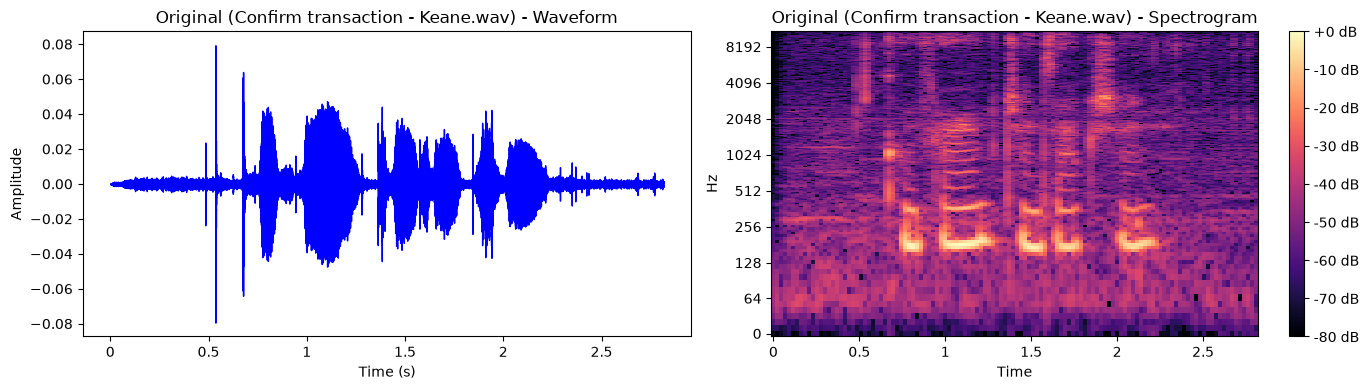

c:\Users\mugab\Multimodel\Formative-2-Multimodal-Data-Preprocessing-Assignment-G19\.venv\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
c:\Users\mugab\Multimodel\Formative-2-Multimodal-Data-Preprocessing-Assignment-G19\.venv\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(


--- Processing: Linda_confirm_transaction.wav (Member: Linda) ---


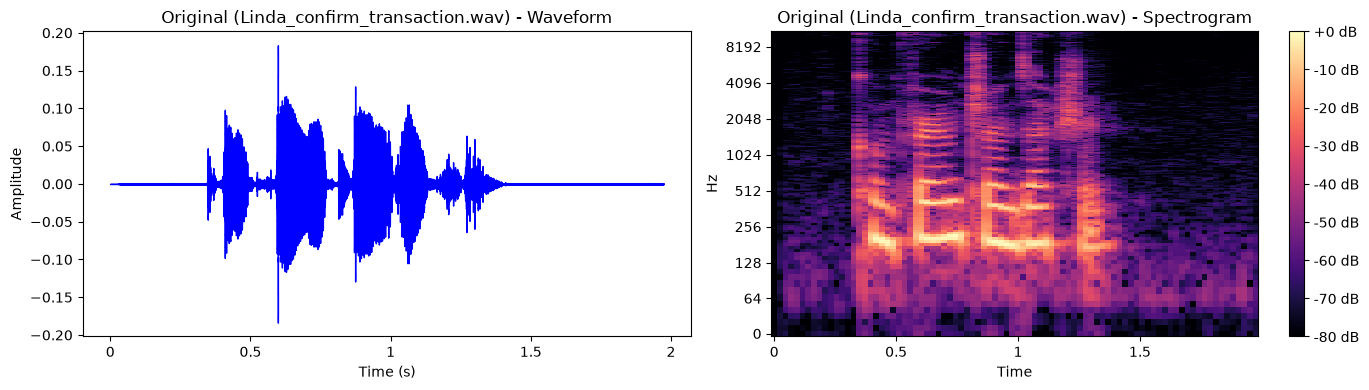

c:\Users\mugab\Multimodel\Formative-2-Multimodal-Data-Preprocessing-Assignment-G19\.venv\Lib\site-packages\numba\np\ufunc\dufunc.py:303: RuntimeWarning: invalid value encountered in cast
  return super().__call__(*args, **kws)


--- Processing: Linda_yes_approve.wav (Member: Linda) ---


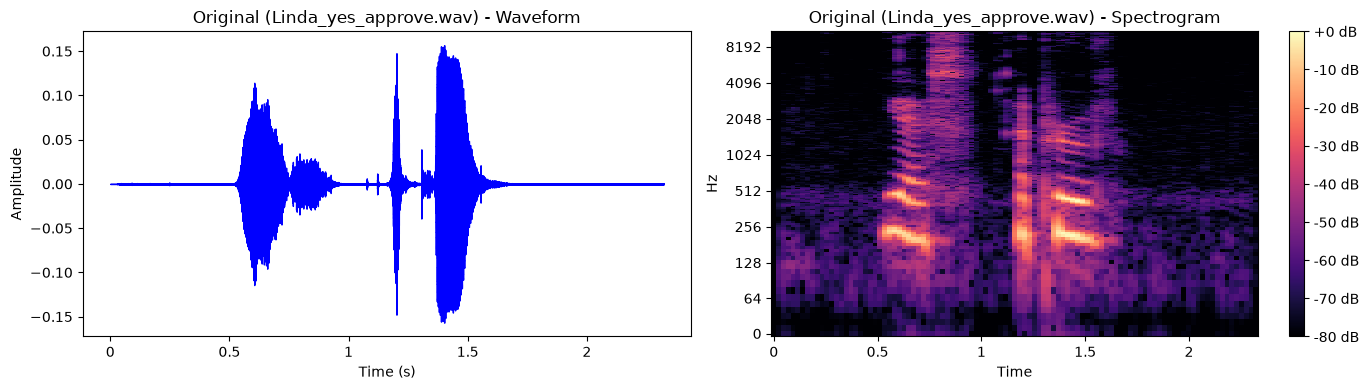

--- Processing: Yes approve - Keane.wav (Member: Yes approve - Keane) ---


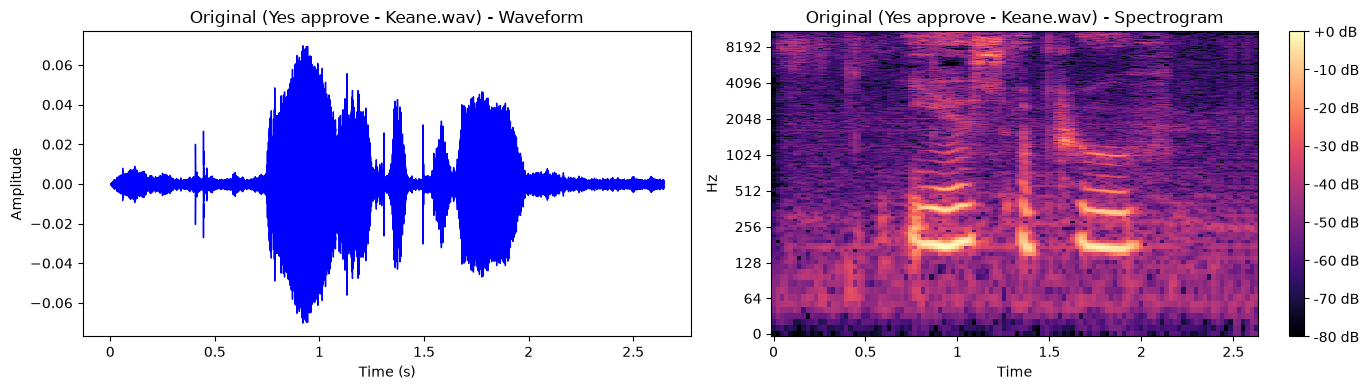


[Success] Execution completed! Saved 16 total records to 'audio_features.csv'.


,filename,member_name,phrase,augmentation,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,mfcc_3_std,...,mfcc_11_mean,mfcc_11_std,mfcc_12_mean,mfcc_12_std,mfcc_13_mean,mfcc_13_std,rolloff_mean,rolloff_std,rms_energy_mean,rms_energy_std
0,Confirm transaction - Keane.wav,Confirm transaction - Keane,Unknown,none,-430.401245,62.662079,51.646893,33.663624,6.566562,18.051981,...,-9.902123,9.929708,-6.860291,10.385299,-6.597787,6.577053,8262.748943,1048.548915,0.006817,0.006290
1,Confirm transaction - Keane.wav,Confirm transaction - Keane,Unknown,pitch_shift,-466.472717,58.340939,50.660469,34.223995,2.029617,17.107798,...,-10.179771,11.235120,-5.962860,9.441904,-3.653107,7.244904,7702.885662,1707.134177,0.003969,0.003266
2,Confirm transaction - Keane.wav,Confirm transaction - Keane,Unknown,time_stretch,-460.141113,59.758347,49.483738,32.133545,6.961240,17.650728,...,-10.711398,9.743785,-8.556082,10.874030,-7.579846,7.478703,8360.266113,997.934532,0.004540,0.003973
3,Confirm transaction - Keane.wav,Confirm transaction - Keane,Unknown,added_noise,-299.697994,16.064009,7.746819,14.532745,4.720309,9.543435,...,-3.199203,6.871344,-4.482318,6.774123,-3.015776,5.836526,9184.705390,225.565002,0.009231,0.005111
4,Linda_confirm_transaction.wav,Linda,confirm_transaction,none,-526.618530,140.868927,93.048126,54.227863,4.250154,27.613951,...,-3.750862,9.102750,-4.770883,9.555448,-2.146595,7.977129,4605.851994,2475.777312,0.013209,0.014907
5,Linda_confirm_transaction.wav,Linda,confirm_transaction,pitch_shift,-545.669006,146.108734,88.732094,50.198868,4.723968,24.972448,...,-3.660116,11.313307,-1.504521,7.442466,-2.095062,8.320693,4622.377475,2119.678193,0.009313,0.010454
6,Linda_confirm_transaction.wav,Linda,confirm_transaction,time_stretch,-540.814880,142.618484,89.048576,46.758686,7.309135,25.111805,...,-4.100703,8.312872,-4.997304,9.902581,-1.386336,6.083838,4577.551599,2195.379456,0.009309,0.010130
7,Linda_confirm_transaction.wav,Linda,confirm_transaction,added_noise,-292.154935,29.615301,19.111298,26.072038,9.731812,15.286738,...,-4.232588,5.412733,-3.827979,5.781335,-1.648309,5.283786,8685.392442,845.497635,0.015705,0.013179
8,Linda_yes_approve.wav,Linda,yes_approve,none,-556.854980,119.026833,65.162552,56.290371,10.796749,20.738413,...,-2.283361,6.908078,-1.872730,8.941236,-3.927138,9.231485,5664.405022,2569.785730,0.009920,0.017085
9,Linda_yes_approve.wav,Linda,yes_approve,pitch_shift,-587.518066,124.524155,70.434906,54.665272,6.068223,22.605839,...,0.977842,8.286483,-2.828558,9.673196,-2.086433,8.850883,5317.315372,2236.740697,0.006971,0.010962


In [23]:
# ---------------------------------------------------------
# 5. EXECUTION ENTRY POINT
# ---------------------------------------------------------
# Set directory path to match your folder structure (audio_data)
audio_directory = "audio_data"

if os.path.exists(audio_directory):
    audio_df = process_sound_dataset(audio_directory)
    if audio_df is not None:
        display(audio_df.head(10))
else:
    print(f"Directory '{audio_directory}' does not exist. Please check your folder structure.")